# Card fraud detection with the Feast feature store: Option 2: a single transaction-keyed feature view

This notebook builds a baseline credit-card fraud detection model on top of [Feast](https://github.com/feast-dev/feast). It covers four steps:

1. **Feature creation.** It computes the baseline features from the [Fraud Detection Handbook, Chapter 3](https://github.com/Fraud-Detection-Handbook/fraud-detection-handbook/blob/81cf7d1714bb7b2f5b496407d9055d91dc68dc25/Chapter_3_GettingStarted/BaselineFeatureTransformation.ipynb) and stores them as Parquet files, partitioned by day (`date=%Y-%m-%d`), on the local file system. That directory is the Feast **offline store**'s data.
2. **Feature registration.** It declares entities, data sources, feature views (including an on-demand feature view defined with a decorator) and a feature service, and registers them in the Feast **registry**.
3. **Training dataset creation.** It builds an **entity dataframe** and asks Feast for a **point-in-time correct** training dataset.
4. **Model training.** It trains and evaluates a few classifiers, as in the handbook's `BaselineModeling` notebook.

In this notebook, all stored features are attached to **a single entity, the transaction**:

| Feature view | Entity (join key) | Features |
|---|---|---|
| `transaction_all_features` | transaction (`TRANSACTION_ID`) | `TX_AMOUNT`, 6 customer spending features, 6 terminal risk features |
| `transaction_datetime_features` (on demand) | computed from the request's `event_timestamp` | `TX_DURING_WEEKEND`, `TX_DURING_NIGHT` |

This is the simplest possible design. Each training example is a lookup by transaction ID.

The sibling notebook [01_fraud_detection_feast_natural_entities.ipynb](01_fraud_detection_feast_natural_entities.ipynb) shows Option 1, with natural entities (transaction, customer, terminal). The overall flow follows the Feast [GCP fraud tutorial](https://github.com/feast-dev/feast-gcp-fraud-tutorial/blob/main/notebooks/Fraud_Detection_Tutorial.ipynb), with a local offline store in place of BigQuery.

## 0. Setup

In [1]:
import datetime
import os
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn import metrics

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="On demand feature view is an experimental feature")
pd.set_option("display.max_columns", 30)

# Raw transactions (one CSV per day): <RAW_DATA_DIR>/date=%Y-%m-%d/data.csv
RAW_DATA_DIR = Path("/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-raw")
# Transformed transactions read by the Feast offline store: <TRANSFORMED_DATA_DIR>/date=%Y-%m-%d/data.parquet
TRANSFORMED_DATA_DIR = Path("/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed")
# Feast feature repository for this option (feature_store.yaml + feature definitions)
REPO_PATH = Path("../feature_repo_option2").resolve()
# The `feast` CLI installed in the same environment as this kernel
FEAST_CLI = Path(sys.executable).parent / "feast"


def feast_cli(*args):
    # Run a `feast` CLI command from the feature repository and print its output
    result = subprocess.run(
        [str(FEAST_CLI), *args],
        cwd=REPO_PATH,
        capture_output=True,
        text=True,
        env={**os.environ, "PYTHONWARNINGS": "ignore"},
    )
    print(result.stdout + result.stderr)


import feast

print("feast", feast.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

feast 0.67.0 | pandas 2.3.3 | scikit-learn 1.9.1


## 1. Load the raw transactions

The raw data has one CSV file per day, stored in a hive-style partition folder such as `date=2018-04-01/data.csv`.

In [2]:
def read_raw_transactions(raw_data_dir, begin_date=None, end_date=None):
    # Read the daily CSV partitions between begin_date and end_date (inclusive, '%Y-%m-%d')
    partitions = sorted(raw_data_dir.glob("date=*"))
    if begin_date:
        partitions = [p for p in partitions if p.name >= f"date={begin_date}"]
    if end_date:
        partitions = [p for p in partitions if p.name <= f"date={end_date}"]

    df = pd.concat(
        [pd.read_csv(p / "data.csv", parse_dates=["TX_DATETIME"]) for p in partitions],
        ignore_index=True,
    )
    return df.sort_values("TX_DATETIME").reset_index(drop=True)


%time transactions_df = read_raw_transactions(RAW_DATA_DIR)
print(
    f"{len(transactions_df)} transactions loaded, containing {transactions_df.TX_FRAUD.sum()} fraudulent transactions "
    f"({transactions_df.TX_DATETIME.min()} -> {transactions_df.TX_DATETIME.max()})"
)
transactions_df.head()

CPU times: user 2.47 s, sys: 584 ms, total: 3.05 s
Wall time: 3.23 s
1754155 transactions loaded, containing 14681 fraudulent transactions (2018-04-01 00:00:31 -> 2018-09-30 23:59:57)


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO
0,0,2018-04-01 00:00:31,596,3156,57.16,31,0,0,0
1,1,2018-04-01 00:02:10,4961,3412,81.51,130,0,0,0
2,2,2018-04-01 00:07:56,2,1365,146.00,476,0,0,0
3,3,2018-04-01 00:09:29,4128,8737,64.49,569,0,0,0
4,4,2018-04-01 00:10:34,927,9906,50.99,634,0,0,0


## 2. Feature creation

The transformations follow the handbook's [BaselineFeatureTransformation](https://github.com/Fraud-Detection-Handbook/fraud-detection-handbook/blob/81cf7d1714bb7b2f5b496407d9055d91dc68dc25/Chapter_3_GettingStarted/BaselineFeatureTransformation.ipynb) notebook. They fall into two groups:

* The **date/time features** `TX_DURING_WEEKEND` and `TX_DURING_NIGHT` depend only on the transaction's own timestamp. Feast can compute them for us at retrieval time with an **on-demand feature view**, a Python function registered with the `@on_demand_feature_view` decorator (section 4). They are **not** stored.
* The **windowed features** (customer spending behaviour, terminal risk) depend on the history of other transactions. We precompute them here with pandas and store them in the offline store (section 3).

### 2.1 Date and time transformations (reference implementation)

* `TX_DURING_WEEKEND` is 1 if the transaction happens on a weekend and 0 on a weekday.
* `TX_DURING_NIGHT` is 1 if the transaction happens at night (hour ≤ 6, from midnight to 6am, as in the handbook) and 0 during the day.

These are the handbook's functions. We keep them only to check, in section 6, the values that Feast's on-demand feature view computes.

In [3]:
def is_weekend(tx_datetime):
    # Transform date into weekday (0 is Monday, 6 is Sunday)
    weekday = tx_datetime.weekday()
    # Binary value: 0 if weekday, 1 if weekend
    return int(weekday >= 5)


def is_night(tx_datetime):
    # Binary value: 1 if hour less than or equal to 6, and 0 otherwise
    return int(tx_datetime.hour <= 6)


transactions_df.TX_DATETIME.head().to_frame().assign(
    TX_DURING_WEEKEND=lambda df: df.TX_DATETIME.apply(is_weekend),
    TX_DURING_NIGHT=lambda df: df.TX_DATETIME.apply(is_night),
)

,TX_DATETIME,TX_DURING_WEEKEND,TX_DURING_NIGHT
0,2018-04-01 00:00:31,1,1
1,2018-04-01 00:02:10,1,1
2,2018-04-01 00:07:56,1,1
3,2018-04-01 00:09:29,1,1
4,2018-04-01 00:10:34,1,1


### 2.2 Customer ID transformations: spending behaviour

For each customer, and for windows of 1, 7 and 30 days that end at the current transaction (inclusive), compute:

* `CUSTOMER_ID_NB_TX_<w>DAY_WINDOW`: the number of transactions (*frequency*).
* `CUSTOMER_ID_AVG_AMOUNT_<w>DAY_WINDOW`: the average amount spent (*monetary value*).

That gives six features.

In [4]:
def get_customer_spending_behaviour_features(customer_transactions, windows_size_in_days=[1, 7, 30]):
    # Let us first order transactions chronologically
    customer_transactions = customer_transactions.sort_values("TX_DATETIME")

    # The transaction date and time is set as the index, which will allow the use of the rolling function
    customer_transactions.index = customer_transactions.TX_DATETIME

    for window_size in windows_size_in_days:
        # Compute the sum of the transaction amounts and the number of transactions for the given window size
        SUM_AMOUNT_TX_WINDOW = customer_transactions["TX_AMOUNT"].rolling(str(window_size) + "d").sum()
        NB_TX_WINDOW = customer_transactions["TX_AMOUNT"].rolling(str(window_size) + "d").count()

        # Compute the average transaction amount for the given window size
        # NB_TX_WINDOW is always >0 since current transaction is always included
        AVG_AMOUNT_TX_WINDOW = SUM_AMOUNT_TX_WINDOW / NB_TX_WINDOW

        customer_transactions["CUSTOMER_ID_NB_TX_" + str(window_size) + "DAY_WINDOW"] = list(NB_TX_WINDOW)
        customer_transactions["CUSTOMER_ID_AVG_AMOUNT_" + str(window_size) + "DAY_WINDOW"] = list(AVG_AMOUNT_TX_WINDOW)

    # Reindex according to transaction IDs
    customer_transactions.index = customer_transactions.TRANSACTION_ID

    return customer_transactions


get_customer_spending_behaviour_features(transactions_df[transactions_df.CUSTOMER_ID == 0]).head(10)

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW
TRANSACTION_ID,,,,,,,,,,,,,,,
1758,1758,2018-04-01 07:19:05,0,6076,123.59,26345,0,0,0,1.0,123.590000,1.0,123.590000,1.0,123.590000
8275,8275,2018-04-01 18:00:16,0,858,77.34,64816,0,0,0,2.0,100.465000,2.0,100.465000,2.0,100.465000
8640,8640,2018-04-01 19:02:02,0,6698,46.51,68522,0,0,0,3.0,82.480000,3.0,82.480000,3.0,82.480000
12169,12169,2018-04-02 08:51:06,0,6569,54.72,118266,1,0,0,3.0,59.523333,4.0,75.540000,4.0,75.540000
15764,15764,2018-04-02 14:05:38,0,7707,63.30,137138,1,0,0,4.0,60.467500,5.0,73.092000,5.0,73.092000
16470,16470,2018-04-02 15:13:02,0,3096,32.35,141182,1,0,0,5.0,54.844000,6.0,66.301667,6.0,66.301667
16810,16810,2018-04-02 15:46:51,0,7502,13.59,143211,1,0,0,6.0,47.968333,7.0,58.771429,7.0,58.771429
18572,18572,2018-04-02 20:24:47,0,3457,51.89,159887,1,0,0,5.0,43.170000,8.0,57.911250,8.0,57.911250
21219,21219,2018-04-03 07:41:24,0,7618,93.26,200484,2,0,0,6.0,51.518333,9.0,61.838889,9.0,61.838889


In [5]:
%time transactions_df = transactions_df.groupby("CUSTOMER_ID", group_keys=False).apply(get_customer_spending_behaviour_features)
transactions_df = transactions_df.sort_values("TX_DATETIME").reset_index(drop=True)

CPU times: user 18 s, sys: 339 ms, total: 18.4 s
Wall time: 18.5 s


### 2.3 Terminal ID transformations: risk scores

For each terminal, compute a **risk score**: the share of fraudulent transactions on that terminal over windows of 1, 7 and 30 days.

These windows don't end at the current transaction. They are **shifted back by a delay period of 7 days**, because fraud labels only become known after an investigation or a customer complaint. The window for size *w* therefore covers `[t - (delay + w), t - delay]`.

The six features are `TERMINAL_ID_NB_TX_<w>DAY_WINDOW` and `TERMINAL_ID_RISK_<w>DAY_WINDOW`. A risk is undefined when the window holds no transactions; those values are set to 0.

In [6]:
def get_count_risk_rolling_window(terminal_transactions, delay_period=7, windows_size_in_days=[1, 7, 30], feature="TERMINAL_ID"):
    terminal_transactions = terminal_transactions.sort_values("TX_DATETIME")

    terminal_transactions.index = terminal_transactions.TX_DATETIME

    NB_FRAUD_DELAY = terminal_transactions["TX_FRAUD"].rolling(str(delay_period) + "d").sum()
    NB_TX_DELAY = terminal_transactions["TX_FRAUD"].rolling(str(delay_period) + "d").count()

    for window_size in windows_size_in_days:
        NB_FRAUD_DELAY_WINDOW = terminal_transactions["TX_FRAUD"].rolling(str(delay_period + window_size) + "d").sum()
        NB_TX_DELAY_WINDOW = terminal_transactions["TX_FRAUD"].rolling(str(delay_period + window_size) + "d").count()

        NB_FRAUD_WINDOW = NB_FRAUD_DELAY_WINDOW - NB_FRAUD_DELAY
        NB_TX_WINDOW = NB_TX_DELAY_WINDOW - NB_TX_DELAY

        RISK_WINDOW = NB_FRAUD_WINDOW / NB_TX_WINDOW

        terminal_transactions[feature + "_NB_TX_" + str(window_size) + "DAY_WINDOW"] = list(NB_TX_WINDOW)
        terminal_transactions[feature + "_RISK_" + str(window_size) + "DAY_WINDOW"] = list(RISK_WINDOW)

    terminal_transactions.index = terminal_transactions.TRANSACTION_ID

    # Replace NA values with 0 (all undefined risk scores where NB_TX_WINDOW is 0)
    terminal_transactions.fillna(0, inplace=True)

    return terminal_transactions


get_count_risk_rolling_window(transactions_df[transactions_df.TERMINAL_ID == 3059]).query("TX_FRAUD == 1").head(10)

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW
TRANSACTION_ID,,,,,,,,,,,,,,,,,,,,,
3527,3527,2018-04-01 10:17:43,3774,3059,225.41,37063,0,1,1,3.0,158.073333,3.0,158.073333,3.0,158.073333,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
%time transactions_df = transactions_df.groupby("TERMINAL_ID", group_keys=False).apply(get_count_risk_rolling_window)
transactions_df = transactions_df.sort_values("TX_DATETIME").reset_index(drop=True)
transactions_df

CPU times: user 42 s, sys: 535 ms, total: 42.6 s
Wall time: 42.8 s


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_AMOUNT,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW
0,0,2018-04-01 00:00:31,596,3156,57.16,31,0,0,0,1.0,57.160000,1.0,57.160000,1.0,57.160000,0.0,0.0,0.0,0.0,0.0,0.00000
1,1,2018-04-01 00:02:10,4961,3412,81.51,130,0,0,0,1.0,81.510000,1.0,81.510000,1.0,81.510000,0.0,0.0,0.0,0.0,0.0,0.00000
2,2,2018-04-01 00:07:56,2,1365,146.00,476,0,0,0,1.0,146.000000,1.0,146.000000,1.0,146.000000,0.0,0.0,0.0,0.0,0.0,0.00000
3,3,2018-04-01 00:09:29,4128,8737,64.49,569,0,0,0,1.0,64.490000,1.0,64.490000,1.0,64.490000,0.0,0.0,0.0,0.0,0.0,0.00000
4,4,2018-04-01 00:10:34,927,9906,50.99,634,0,0,0,1.0,50.990000,1.0,50.990000,1.0,50.990000,0.0,0.0,0.0,0.0,0.0,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1754150,1754150,2018-09-30 23:56:36,161,655,54.24,15810996,182,0,0,2.0,75.280000,12.0,67.047500,72.0,69.521111,1.0,0.0,4.0,0.0,28.0,0.00000
1754151,1754151,2018-09-30 23:57:38,4342,6181,1.23,15811058,182,0,0,1.0,1.230000,21.0,22.173810,93.0,24.780753,1.0,0.0,9.0,0.0,39.0,0.00000
1754152,1754152,2018-09-30 23:58:21,618,1502,6.62,15811101,182,0,0,5.0,7.368000,21.0,7.400476,65.0,7.864462,1.0,0.0,5.0,0.0,33.0,0.00000
1754153,1754153,2018-09-30 23:59:52,4056,3067,55.40,15811192,182,0,0,3.0,100.696667,16.0,107.052500,51.0,102.919608,1.0,0.0,6.0,0.0,28.0,0.00000


### 2.4 Why not let Feast compute the windowed features too?

Feast has two other ways to define transformations, and neither can produce these features as training data with a local setup (Feast 0.67):

* **`Aggregation(column, function, time_window)`** on a `BatchFeatureView` / `StreamFeatureView` ([docs](https://docs.feast.dev/getting-started/architecture/feature-transformation)). Only the **batch compute engine** runs aggregations, and only when it materializes features to the online store. `get_historical_features` never runs them.
  * The default `local` engine rejects time windows outright: *"Time window aggregation is not supported in the local compute engine"*.
  * Choosing DuckDB as the offline store doesn't change this, because the compute engine is a separate setting (`batch_engine:`).
  * The Spark and Ray engines do support windows, but as tumbling/sliding tiles for materialization snapshots. They don't give a rolling value that ends at each transaction.
* **`@batch_feature_view(udf=...)`** also runs in the compute engine during materialization. The DuckDB and Dask offline stores ignore the UDF in `get_historical_features`.

The terminal risk score is also a *ratio* over a window *shifted back by a delay* and built from the *label*. No single built-in aggregation function expresses that.

So we keep the handbook's pandas code for the windowed features and let Feast manage storage, registration, point-in-time joins and serving.

## 3. Write the features to the offline store

The transformed transactions go to `simulated-data-transformed/date=%Y-%m-%d/data.parquet`, one partition per day.

Feast's `FileSource` reads **Parquet** (or Delta), not CSV, which is why the features are written as Parquet even though the raw data is CSV. Each row keeps:
* the entity keys (`TRANSACTION_ID`, `CUSTOMER_ID`, `TERMINAL_ID`)
* the event timestamp (`TX_DATETIME`), which Feast uses for point-in-time joins
* `TX_AMOUNT` and the 12 windowed features

The fraud label `TX_FRAUD` is left out on purpose. Labels come with the **entity dataframe** (section 5), so no feature can be read straight from the label. Both notebooks write identical files, so either one can run first.

In [8]:
STORED_FEATURES = [
    "TX_AMOUNT",
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW",
    "TERMINAL_ID_NB_TX_1DAY_WINDOW", "TERMINAL_ID_RISK_1DAY_WINDOW",
    "TERMINAL_ID_NB_TX_7DAY_WINDOW", "TERMINAL_ID_RISK_7DAY_WINDOW",
    "TERMINAL_ID_NB_TX_30DAY_WINDOW", "TERMINAL_ID_RISK_30DAY_WINDOW",
]
OFFLINE_STORE_COLUMNS = ["TRANSACTION_ID", "TX_DATETIME", "CUSTOMER_ID", "TERMINAL_ID", "TX_TIME_DAYS"] + STORED_FEATURES


def write_partitioned_parquet(df, output_dir):
    # Write one Parquet file per day under output_dir/date=%Y-%m-%d/ (existing partitions are replaced)
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True)

    for day, day_df in df.groupby(df.TX_DATETIME.dt.strftime("%Y-%m-%d")):
        partition_dir = output_dir / f"date={day}"
        partition_dir.mkdir()
        day_df.sort_values("TX_DATETIME").to_parquet(partition_dir / "data.parquet", index=False)


%time write_partitioned_parquet(transactions_df[OFFLINE_STORE_COLUMNS], TRANSFORMED_DATA_DIR)
partitions = sorted(p.name for p in TRANSFORMED_DATA_DIR.glob("date=*"))
print(f"{len(partitions)} partitions written: {partitions[0]} ... {partitions[-1]}")
pd.read_parquet(TRANSFORMED_DATA_DIR / "date=2018-09-29").head()

CPU times: user 3.53 s, sys: 550 ms, total: 4.08 s
Wall time: 4.01 s
183 partitions written: date=2018-04-01 ... date=2018-09-30


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,TX_TIME_DAYS,TX_AMOUNT,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW
0,1735083,2018-09-29 00:02:36,3103,1894,181,30.90,3.0,20.196667,18.0,17.080000,69.0,16.097971,1.0,0.0,2.0,0.0,29.0,0.000000
1,1735084,2018-09-29 00:02:43,996,2148,181,9.63,1.0,9.630000,1.0,9.630000,6.0,9.068333,1.0,0.0,12.0,0.0,47.0,0.021277
2,1735085,2018-09-29 00:04:08,4116,1396,181,14.95,3.0,48.883333,30.0,51.372333,113.0,60.813186,1.0,0.0,7.0,0.0,23.0,0.000000
3,1735086,2018-09-29 00:06:53,2500,8655,181,13.33,1.0,13.330000,1.0,13.330000,3.0,62.880000,3.0,0.0,9.0,0.0,30.0,0.000000
4,1735087,2018-09-29 00:11:34,26,4522,181,116.14,3.0,59.650000,10.0,78.349000,69.0,67.518406,3.0,0.0,8.0,0.0,22.0,0.000000


## 4. Register the features in Feast

### 4.1 The feature repository

A Feast *feature repository* is a folder with a `feature_store.yaml` and one or more Python files that define the features:

```
feature_repo_option2/
├── feature_store.yaml        # project, registry, offline store, online store
├── feature_store_dask.yaml   # same, with the Dask offline store (used for a comparison in section 6)
└── features.py               # entities, data sources, feature views, feature service
```

### 4.2 Choice of the offline store

The offline store is the component that runs `get_historical_features` (point-in-time joins) and reads data for materialization. Feast offers several implementations that work on **local files**:

| `offline_store.type` | Implementation | Data source | Notes |
|---|---|---|---|
| `file` (alias `dask`) | `DaskOfflineStore` | `FileSource` (Parquet/Delta) | Feast's default. Pure Python with no extra dependencies. It merges every entity row with *every* source row of the same key before filtering by time, so it is slow and memory-hungry on this dataset. |
| `duckdb` | `DuckDBOfflineStore` | `FileSource` (Parquet/Delta) | In-process SQL engine (ibis + DuckDB). Needs `feast[duckdb]`. |
| `spark` | `SparkOfflineStore` (contrib) | `SparkSource` (Parquet, CSV, …) | Spark in local mode. Heavier, since it needs Java and PySpark. |
| `ray` | `RayOfflineStore` (contrib) | `FileSource` | Distributed processing with Ray. Contrib, so newer and less mature. |

This notebook uses **`type: duckdb`**. Measured on this dataset, the 21-day Option 1 training set takes about 10 s with DuckDB and about 1.5 h with Dask (about 5 min per day of entities). Both stores read the same `FileSource` and return the same values. Section 6 runs one day on Dask to show this.

In [9]:
print((REPO_PATH / "feature_store.yaml").read_text())

project: fraud_detection_option2
# The registry stores the feature definitions (entities, sources, feature views, ...) applied with `feast apply`
registry: data/registry.db
provider: local
# Offline store: point-in-time joins over the local Parquet files, run in-process by DuckDB
offline_store:
    type: duckdb
# Online store: only needed for low-latency serving (materialize + get_online_features)
online_store:
    type: sqlite
    path: data/online_store.db
entity_key_serialization_version: 3
auth:
    type: no_auth



### 4.3 Feature definitions

`features.py` declares the following objects:

* **Entity**: `transaction`, with join key `TRANSACTION_ID`, the column name used in both the data source and the entity dataframe.
* **Data sources**:
  * `transformed_transactions_source`: a `FileSource` pointing to the partitioned Parquet directory. Its `timestamp_field` (`TX_DATETIME`) is the event time used for point-in-time joins.
  * `transaction_request`: a `RequestSource`, i.e. data supplied with each request rather than read from storage. Here that's the transaction's `event_timestamp`.
* **Feature view** `transaction_all_features`, with a `schema` (13 features), a `ttl` of 1 day, `tags` and a `description`. The row for a transaction carries that transaction's own timestamp, so a short TTL is enough.
* **On-demand feature view** `transaction_datetime_features`: defined with the `@on_demand_feature_view` decorator. Feast runs the decorated pandas function at retrieval time, both offline and online.
* **Feature service** `fraud_model_v2`: the named set of features the model consumes.

One detail of the on-demand feature view: it reads the request's `event_timestamp`, not a column named `TX_DATETIME`. During `get_historical_features`, the offline store drops any entity-dataframe column that has the same name as the source's `timestamp_field`. The entity row's `event_timestamp` *is* the transaction time anyway.

Also note that the ODFV schema fields have no `description`. `feast apply` compares the declared fields with the fields it infers from running the function, and that comparison includes the description.

In [10]:
print((REPO_PATH / "features.py").read_text())

"""Feast feature definitions for card-fraud detection - Option 2: a single transaction-keyed view.

All stored features are attached to the transaction:

* ``transaction_all_features``       keyed on TRANSACTION_ID (amount, customer spending behaviour and
  terminal risk scores)
* ``transaction_datetime_features``  an on-demand feature view computing the weekend/night flags
  from the transaction timestamp at retrieval time

The windowed customer/terminal features are computed in the notebook (following the Fraud Detection
Handbook, Chapter 3) and written as Parquet files partitioned by day (``date=%Y-%m-%d``).
"""

from datetime import timedelta

import pandas as pd

from feast import Entity, FeatureService, FeatureView, Field, FileSource, RequestSource, ValueType
from feast.data_format import ParquetFormat
from feast.on_demand_feature_view import on_demand_feature_view
from feast.types import Float64, Int64, UnixTimestamp

TRANSFORMED_DATA_DIR = "/Users/mesfinmulugeta/projects/person

### 4.4 Registering with the CLI: `feast plan` / `feast apply`

`feast plan` shows what *would* change in the registry. `feast apply` scans the repository's Python files for Feast objects, validates them, writes them to the **registry** (`data/registry.db`, as set in `feature_store.yaml`) and creates the online store tables.

In [11]:
feast_cli("plan")

No project found in the repository. Using project name fraud_detection_option2 defined in feature_store.yaml
No changes to registry
No changes to infrastructure
/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/feast/feature_store.py:1165: RuntimeWarning: On demand feature view is an experimental feature. This API is stable, but the functionality does not scale well for offline retrieval
  warnings.warn(



In [12]:
feast_cli("apply")

No project found in the repository. Using project name fraud_detection_option2 defined in feature_store.yaml
Applying changes for project fraud_detection_option2
No changes to registry
No changes to infrastructure
/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/feast/feature_store.py:1165: RuntimeWarning: On demand feature view is an experimental feature. This API is stable, but the functionality does not scale well for offline retrieval
  warnings.warn(



### 4.5 Inspecting the registry

**From the CLI:**

In [13]:
feast_cli("entities", "list")
feast_cli("data-sources", "list")
feast_cli("feature-views", "list")
feast_cli("on-demand-feature-views", "list")
feast_cli("feature-services", "list")

NAME         DESCRIPTION                 TYPE
transaction  A card payment transaction  ValueType.INT64



NAME                             CLASS
transformed_transactions_source  <class 'feast.infra.offline_stores.file_source.FileSource'>
transaction_request              <class 'feast.data_source.RequestSource'>



NAME                           ENTITIES         TYPE                 ENABLED    STATE
transaction_all_features       {'transaction'}  FeatureView          Yes        STATE_UNSPECIFIED
transaction_datetime_features  n/a              OnDemandFeatureView  Yes        STATE_UNSPECIFIED



NAME
transaction_datetime_features



NAME            FEATURES
fraud_model_v2  transaction_all_features:TX_AMOUNT, transaction_all_features:CUSTOMER_ID_NB_TX_1DAY_WINDOW, transaction_all_features:CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW, transaction_all_features:CUSTOMER_ID_NB_TX_7DAY_WINDOW, transaction_all_features:CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW, transaction_all_features:CUSTOMER_ID_NB_TX_30DAY_WINDOW, transaction_all_features:CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW, transaction_all_features:TERMINAL_ID_NB_TX_1DAY_WINDOW, transaction_all_features:TERMINAL_ID_RISK_1DAY_WINDOW, transaction_all_features:TERMINAL_ID_NB_TX_7DAY_WINDOW, transaction_all_features:TERMINAL_ID_RISK_7DAY_WINDOW, transaction_all_features:TERMINAL_ID_NB_TX_30DAY_WINDOW, transaction_all_features:TERMINAL_ID_RISK_30DAY_WINDOW, transaction_datetime_features:TX_DURING_WEEKEND, transaction_datetime_features:TX_DURING_NIGHT



In [14]:
feast_cli("feature-views", "describe", "transaction_all_features")

spec:
  name: transaction_all_features
  entities:
  - transaction
  features:
  - name: TX_AMOUNT
    valueType: DOUBLE
    description: Transaction amount
  - name: CUSTOMER_ID_NB_TX_1DAY_WINDOW
    valueType: DOUBLE
    description: Number of customer transactions in the last 1 day(s)
  - name: CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW
    valueType: DOUBLE
    description: Average customer transaction amount in the last 1 day(s)
  - name: CUSTOMER_ID_NB_TX_7DAY_WINDOW
    valueType: DOUBLE
    description: Number of customer transactions in the last 7 day(s)
  - name: CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW
    valueType: DOUBLE
    description: Average customer transaction amount in the last 7 day(s)
  - name: CUSTOMER_ID_NB_TX_30DAY_WINDOW
    valueType: DOUBLE
    description: Number of customer transactions in the last 30 day(s)
  - name: CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW
    valueType: DOUBLE
    description: Average customer transaction amount in the last 30 day(s)
  - name: TERMINAL_I

**From the Python SDK:** a `FeatureStore` object is the entry point. It reads `feature_store.yaml` and the registry.

In [15]:
from feast import FeatureStore

store = FeatureStore(repo_path=str(REPO_PATH))

print("Entities:               ", [(e.name, e.join_key) for e in store.list_entities()])
print("Data sources:           ", [ds.name for ds in store.list_data_sources()])
print("Feature views:          ", [fv.name for fv in store.list_feature_views()])
print("On-demand feature views:", [odfv.name for odfv in store.list_on_demand_feature_views()])
print("Feature services:       ", [fs.name for fs in store.list_feature_services()])

Entities:                [('transaction', 'TRANSACTION_ID')]
Data sources:            ['transformed_transactions_source', 'transaction_request']
Feature views:           ['transaction_all_features']
On-demand feature views: ['transaction_datetime_features']
Feature services:        ['fraud_model_v2']


In [16]:
# One row per registered feature, with the view it belongs to, its entities / sources, dtype and TTL
pd.DataFrame(
    [
        {
            "view": fv.name,
            "type": "FeatureView",
            "entities / sources": ", ".join(fv.entities),
            "ttl": fv.ttl,
            "feature": field.name,
            "dtype": str(field.dtype),
            "description": field.description,
        }
        for fv in sorted(store.list_feature_views(), key=lambda fv: fv.name)
        for field in fv.features
    ]
    + [
        {
            "view": odfv.name,
            "type": "OnDemandFeatureView",
            "entities / sources": ", ".join(odfv.source_request_sources),
            "ttl": None,
            "feature": field.name,
            "dtype": str(field.dtype),
            "description": odfv.description,
        }
        for odfv in store.list_on_demand_feature_views()
        for field in odfv.features
    ]
)

,view,type,entities / sources,ttl,feature,dtype,description
0,transaction_all_features,FeatureView,transaction,1 days,TX_AMOUNT,Float64,Transaction amount
1,transaction_all_features,FeatureView,transaction,1 days,CUSTOMER_ID_NB_TX_1DAY_WINDOW,Float64,Number of customer transactions in the last 1 ...
2,transaction_all_features,FeatureView,transaction,1 days,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,Float64,Average customer transaction amount in the las...
3,transaction_all_features,FeatureView,transaction,1 days,CUSTOMER_ID_NB_TX_7DAY_WINDOW,Float64,Number of customer transactions in the last 7 ...
4,transaction_all_features,FeatureView,transaction,1 days,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,Float64,Average customer transaction amount in the las...
5,transaction_all_features,FeatureView,transaction,1 days,CUSTOMER_ID_NB_TX_30DAY_WINDOW,Float64,Number of customer transactions in the last 30...
6,transaction_all_features,FeatureView,transaction,1 days,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,Float64,Average customer transaction amount in the las...
7,transaction_all_features,FeatureView,transaction,1 days,TERMINAL_ID_NB_TX_1DAY_WINDOW,Float64,Number of terminal transactions in a 1-day win...
8,transaction_all_features,FeatureView,transaction,1 days,TERMINAL_ID_RISK_1DAY_WINDOW,Float64,Share of fraudulent terminal transactions in a...
9,transaction_all_features,FeatureView,transaction,1 days,TERMINAL_ID_NB_TX_7DAY_WINDOW,Float64,Number of terminal transactions in a 7-day win...


In [17]:
# A feature service references projections of one or more (on-demand) feature views
for fs in store.list_feature_services():
    print(fs.name, "->", {p.name: [f.name for f in p.features] for p in fs.feature_view_projections})

fraud_model_v2 -> {'transaction_all_features': ['TX_AMOUNT', 'CUSTOMER_ID_NB_TX_1DAY_WINDOW', 'CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW', 'CUSTOMER_ID_NB_TX_7DAY_WINDOW', 'CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW', 'CUSTOMER_ID_NB_TX_30DAY_WINDOW', 'CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW', 'TERMINAL_ID_NB_TX_1DAY_WINDOW', 'TERMINAL_ID_RISK_1DAY_WINDOW', 'TERMINAL_ID_NB_TX_7DAY_WINDOW', 'TERMINAL_ID_RISK_7DAY_WINDOW', 'TERMINAL_ID_NB_TX_30DAY_WINDOW', 'TERMINAL_ID_RISK_30DAY_WINDOW'], 'transaction_datetime_features': ['TX_DURING_WEEKEND', 'TX_DURING_NIGHT']}


### 4.6 Registering from Python: `store.apply`

`store.apply([...])` does the same as `feast apply`, but takes the objects directly. Here we import the definitions, add a tag to a feature view, and apply it. The registry now holds the new version. `feast plan` compares the repository files with the registry, so it reports the difference. Running `feast apply` again puts the registry back in sync with `features.py`.

In [18]:
sys.path.insert(0, str(REPO_PATH))
import features as feature_definitions  # noqa: E402  (feature_repo_option2/features.py)

updated_view = feature_definitions.transaction_all_features
updated_view.tags = {**updated_view.tags, "owner": "notebook-demo"}
store.apply([feature_definitions.transaction, feature_definitions.transformed_transactions_source, updated_view])

print("Registry tags after store.apply:", store.get_feature_view("transaction_all_features").tags)
feast_cli("plan")

Registry tags after store.apply: {'team': 'fraud', 'option': '2', 'owner': 'notebook-demo'}


No project found in the repository. Using project name fraud_detection_option2 defined in feature_store.yaml
Updated feature view transaction_all_features
	tags: {'team': 'fraud', 'owner': 'notebook-demo', 'option': '2'} -> {'team': 'fraud', 'option': '2'}
	batch_source: type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
data_source_class_type: "feast.infra.offline_stores.file_source.FileSource"
name: "transformed_transactions_source"
description: "Transactions enriched with the windowed baseline features, partitioned by date=%Y-%m-%d"
meta {
  created_timestamp {
    seconds: 1793297029
    nanos: 27815000
  }
  last_updated_timestamp {
    seconds: 1793297029
    nanos: 41914000
  }
}
 -> type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/per

In [19]:
# Restore the registry to the definitions in features.py
feast_cli("apply")
store = FeatureStore(repo_path=str(REPO_PATH))
print("Registry tags after feast apply:", store.get_feature_view("transaction_all_features").tags)

No project found in the repository. Using project name fraud_detection_option2 defined in feature_store.yaml
Applying changes for project fraud_detection_option2
Updated feature view transaction_all_features
	tags: {'owner': 'notebook-demo', 'team': 'fraud', 'option': '2'} -> {'team': 'fraud', 'option': '2'}
	batch_source: type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {
    }
  }
  uri: "/Users/mesfinmulugeta/projects/personal/card-fraud/simulated-data-transformed"
}
data_source_class_type: "feast.infra.offline_stores.file_source.FileSource"
name: "transformed_transactions_source"
description: "Transactions enriched with the windowed baseline features, partitioned by date=%Y-%m-%d"
meta {
  created_timestamp {
    seconds: 1793297029
    nanos: 27815000
  }
  last_updated_timestamp {
    seconds: 1793297029
    nanos: 41914000
  }
}
 -> type: BATCH_FILE
timestamp_field: "TX_DATETIME"
file_options {
  file_format {
    parquet_format {

You can also browse the registry in a web UI with `feast ui`, run from the feature repository.

## 5. The entity dataframe

To build a training set, Feast needs an **entity dataframe** with:

* the **join key** of the entity used by the requested features: only `TRANSACTION_ID`
* an **`event_timestamp`** column: the moment at which the feature values should be observed. Here that's the transaction time, which is also the request data the on-demand feature view reads.
* any other columns you want to keep: the **label** `TX_FRAUD`, plus `CUSTOMER_ID` and `TX_TIME_DAYS`. Feast doesn't need those last two for the join, but the train/test split and the Card Precision@100 metric do.

We build it from the raw transactions, so each transaction becomes one training example observed at its own timestamp. As in the handbook's `BaselineModeling` notebook, we keep the period from 2018-07-25 to 2018-08-14: 7 days of training, a 7-day delay, and 7 days of test.

In [20]:
BEGIN_DATE, END_DATE = "2018-07-25", "2018-08-14"

entity_df = (
    read_raw_transactions(RAW_DATA_DIR, BEGIN_DATE, END_DATE)
    .rename(columns={"TX_DATETIME": "event_timestamp"})
    [["TRANSACTION_ID", "event_timestamp", "CUSTOMER_ID", "TX_TIME_DAYS", "TX_FRAUD"]]
)
print(f"{len(entity_df)} entity rows, {entity_df.TX_FRAUD.sum()} fraudulent")
entity_df.head()

201295 entity rows, 1792 fraudulent


,TRANSACTION_ID,event_timestamp,CUSTOMER_ID,TX_TIME_DAYS,TX_FRAUD
0,1102483,2018-07-25 00:00:29,1111,115,0
1,1102484,2018-07-25 00:01:08,676,115,0
2,1102485,2018-07-25 00:01:35,402,115,0
3,1102486,2018-07-25 00:01:43,4218,115,0
4,1102487,2018-07-25 00:02:26,3711,115,0


## 6. Generate the training dataset with Feast

`store.get_historical_features(entity_df, features=...)` runs a **point-in-time join**. We pass the feature service `fraud_model_v2`. Passing a list of feature references such as `"<feature_view>:<feature>"` works too.

For every entity row, the point-in-time join picks the feature row with the same `TRANSACTION_ID` whose timestamp is **≤ `event_timestamp`** and **≥ `event_timestamp - ttl`**.

With a single transaction-keyed view, each transaction has exactly one feature row, stamped with the transaction's own time. The join is effectively a lookup by ID. Point-in-time correctness then depends entirely on how the stored features were computed: the customer and terminal windows only look backwards, and the terminal risk is delayed by 7 days. After the join, Feast runs the on-demand feature view on `event_timestamp` to add `TX_DURING_WEEKEND` and `TX_DURING_NIGHT`.

In [21]:
feature_service = store.get_feature_service("fraud_model_v2")

start_time = time.time()
training_df = store.get_historical_features(entity_df=entity_df, features=feature_service).to_df()
print(f"{training_df.shape} retrieved with the DuckDB offline store in {time.time() - start_time:.1f} s")
training_df = training_df.sort_values("TRANSACTION_ID").reset_index(drop=True)
training_df.head()

/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/ibis/backends/duckdb/__init__.py:332: DeprecationWarning: fetch_arrow_table() is deprecated, use to_arrow_table() instead.
  meta = result.fetch_arrow_table()


(201295, 20) retrieved with the DuckDB offline store in 1.2 s


,TRANSACTION_ID,event_timestamp,CUSTOMER_ID,TX_TIME_DAYS,TX_FRAUD,TX_AMOUNT,CUSTOMER_ID_NB_TX_1DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW,CUSTOMER_ID_NB_TX_7DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW,CUSTOMER_ID_NB_TX_30DAY_WINDOW,CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW,TERMINAL_ID_NB_TX_1DAY_WINDOW,TERMINAL_ID_RISK_1DAY_WINDOW,TERMINAL_ID_NB_TX_7DAY_WINDOW,TERMINAL_ID_RISK_7DAY_WINDOW,TERMINAL_ID_NB_TX_30DAY_WINDOW,TERMINAL_ID_RISK_30DAY_WINDOW,TX_DURING_WEEKEND,TX_DURING_NIGHT
0,1102483,2018-07-25 00:00:29+00:00,1111,115,0,40.77,2.0,29.005000,24.0,29.191250,105.0,30.141810,1.0,0.0,10.0,0.0,32.0,0.0,0,1
1,1102484,2018-07-25 00:01:08+00:00,676,115,0,9.62,4.0,25.492500,15.0,19.151333,61.0,18.253607,2.0,0.0,5.0,0.0,27.0,0.0,0,1
2,1102485,2018-07-25 00:01:35+00:00,402,115,0,81.55,6.0,130.778333,11.0,183.875455,50.0,112.001800,0.0,0.0,12.0,0.0,37.0,0.0,0,1
3,1102486,2018-07-25 00:01:43+00:00,4218,115,0,23.10,8.0,19.600000,24.0,21.201667,93.0,19.987849,2.0,0.0,6.0,0.0,22.0,0.0,0,1
4,1102487,2018-07-25 00:02:26+00:00,3711,115,0,59.25,5.0,84.656000,27.0,80.427407,110.0,74.158455,1.0,0.0,10.0,0.0,38.0,0.0,0,1


### 6.1 Checking the on-demand features

The `TX_DURING_WEEKEND` / `TX_DURING_NIGHT` values computed by Feast must match the handbook's `is_weekend` / `is_night` functions:

In [22]:
tx_datetime = training_df.event_timestamp.dt.tz_convert(None)
assert (tx_datetime.apply(is_weekend) == training_df.TX_DURING_WEEKEND).all()
assert (tx_datetime.apply(is_night) == training_df.TX_DURING_NIGHT).all()
print("On-demand features match the handbook definitions for all", len(training_df), "rows")
training_df[["event_timestamp", "TX_DURING_WEEKEND", "TX_DURING_NIGHT"]].sample(5, random_state=0)

On-demand features match the handbook definitions for all 201295 rows


,event_timestamp,TX_DURING_WEEKEND,TX_DURING_NIGHT
56856,2018-07-30 19:44:52+00:00,0,0
35613,2018-07-28 15:02:04+00:00,1,0
127934,2018-08-07 10:02:12+00:00,0,0
156803,2018-08-10 09:42:05+00:00,0,0
158064,2018-08-10 11:35:30+00:00,0,0


### 6.2 Same request with the Dask offline store

`feature_store_dask.yaml` points to the same registry and data source but uses `offline_store: type: file`, Feast's Dask-based default. We run one day of entities through it to compare results and timing. The full 21 days would take far longer.

In [23]:
dask_store = FeatureStore(repo_path=str(REPO_PATH), fs_yaml_file=REPO_PATH / "feature_store_dask.yaml")
one_day_entity_df = entity_df[entity_df.event_timestamp < "2018-07-26"]

start_time = time.time()
one_day_dask_df = dask_store.get_historical_features(entity_df=one_day_entity_df, features=feature_service).to_df()
print(f"Dask offline store: {len(one_day_entity_df)} entity rows in {time.time() - start_time:.1f} s")

start_time = time.time()
one_day_duckdb_df = store.get_historical_features(entity_df=one_day_entity_df, features=feature_service).to_df()
print(f"DuckDB offline store: {len(one_day_entity_df)} entity rows in {time.time() - start_time:.1f} s")

MODEL_FEATURES = STORED_FEATURES + ["TX_DURING_WEEKEND", "TX_DURING_NIGHT"]
one_day_dask_df = one_day_dask_df.sort_values("TRANSACTION_ID").reset_index(drop=True)
one_day_duckdb_df = one_day_duckdb_df.sort_values("TRANSACTION_ID").reset_index(drop=True)
different = ~np.isclose(one_day_dask_df[MODEL_FEATURES], one_day_duckdb_df[MODEL_FEATURES]).all(axis=1)
print(f"Rows with different feature values between Dask and DuckDB: {different.sum()} / {len(one_day_entity_df)}")

Dask offline store: 9541 entity rows in 39.5 s
DuckDB offline store: 9541 entity rows in 0.2 s


Rows with different feature values between Dask and DuckDB: 0 / 9541


/Users/mesfinmulugeta/.local/share/virtualenvs/fraud-detection-using-feast-Ti0pUPAC/lib/python3.12/site-packages/ibis/backends/duckdb/__init__.py:332: DeprecationWarning: fetch_arrow_table() is deprecated, use to_arrow_table() instead.
  meta = result.fetch_arrow_table()


### 6.3 Saving the training dataset

We save a copy of the training set as Parquet so it can be reused without querying Feast again.

In [24]:
training_df["TX_DATETIME"] = training_df.event_timestamp.dt.tz_convert(None)
training_df = training_df.sort_values("TX_DATETIME").reset_index(drop=True)

training_dataset_path = REPO_PATH / "data" / "training_dataset.parquet"
training_df.to_parquet(training_dataset_path, index=False)
print("Training dataset saved to", training_dataset_path)

Training dataset saved to /Users/mesfinmulugeta/projects/personal/fraud-detection-using-feast/feature_repo_option2/data/training_dataset.parquet


## 7. Train / test split

As in the handbook, we train on 7 days starting 2018-07-25, skip a 7-day delay period, and test on the next 7 days. Cards already known to be compromised when a test day starts (frauds found in the training set or in the delay period) are removed from that day's test data.

In [25]:
def get_train_test_set(transactions_df, start_date_training, delta_train=7, delta_delay=7, delta_test=7):
    # Get the training set data
    train_df = transactions_df[
        (transactions_df.TX_DATETIME >= start_date_training)
        & (transactions_df.TX_DATETIME < start_date_training + datetime.timedelta(days=delta_train))
    ]

    # Get the test set data
    test_df = []

    # Note: Cards known to be compromised after the delay period are removed from the test set
    # That is, for each test day, all frauds known at (test_day-delay_period) are removed

    # First, get known defrauded customers from the training set
    known_defrauded_customers = set(train_df[train_df.TX_FRAUD == 1].CUSTOMER_ID)

    # Get the relative starting day of training set (easier than TX_DATETIME to collect test data)
    start_tx_time_days_training = train_df.TX_TIME_DAYS.min()

    for day in range(delta_test):
        # Get test data for that day
        test_df_day = transactions_df[
            transactions_df.TX_TIME_DAYS == start_tx_time_days_training + delta_train + delta_delay + day
        ]

        # Compromised cards from that test day, minus the delay period, are added to the pool of known defrauded customers
        test_df_day_delay_period = transactions_df[
            transactions_df.TX_TIME_DAYS == start_tx_time_days_training + delta_train + day - 1
        ]

        new_defrauded_customers = set(test_df_day_delay_period[test_df_day_delay_period.TX_FRAUD == 1].CUSTOMER_ID)
        known_defrauded_customers = known_defrauded_customers.union(new_defrauded_customers)

        test_df_day = test_df_day[~test_df_day.CUSTOMER_ID.isin(known_defrauded_customers)]

        test_df.append(test_df_day)

    test_df = pd.concat(test_df)

    # Sort data sets by ascending order of transaction ID
    train_df = train_df.sort_values("TRANSACTION_ID")
    test_df = test_df.sort_values("TRANSACTION_ID")

    return (train_df, test_df)


start_date_training = datetime.datetime.strptime(BEGIN_DATE, "%Y-%m-%d")
(train_df, test_df) = get_train_test_set(training_df, start_date_training, delta_train=7, delta_delay=7, delta_test=7)

print(f"Train: {train_df.shape}, {train_df.TX_FRAUD.sum()} frauds")
print(f"Test:  {test_df.shape}, {test_df.TX_FRAUD.sum()} frauds")

Train: (67240, 21), 598 frauds
Test:  (58264, 21), 385 frauds


## 8. Model training and evaluation

The 15 features fetched from Feast are the model inputs: 13 stored features and 2 on-demand features. `TX_FRAUD` is the output. Inputs are standardised.

Performance is measured with:
* **AUC ROC**
* **Average Precision**
* **Card Precision@100**: the share of truly compromised cards among the 100 most suspicious cards each day, averaged over the test days. It is defined in Chapter 4 of the handbook.

In [26]:
input_features = [
    "TX_AMOUNT", "TX_DURING_WEEKEND", "TX_DURING_NIGHT",
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW",
    "TERMINAL_ID_NB_TX_1DAY_WINDOW", "TERMINAL_ID_RISK_1DAY_WINDOW",
    "TERMINAL_ID_NB_TX_7DAY_WINDOW", "TERMINAL_ID_RISK_7DAY_WINDOW",
    "TERMINAL_ID_NB_TX_30DAY_WINDOW", "TERMINAL_ID_RISK_30DAY_WINDOW",
]
output_feature = "TX_FRAUD"


def scaleData(train, test, features):
    scaler = sklearn.preprocessing.StandardScaler()
    scaler.fit(train[features])
    train[features] = scaler.transform(train[features])
    test[features] = scaler.transform(test[features])
    return (train, test)


def fit_model_and_get_predictions(classifier, train_df, test_df, input_features, output_feature="TX_FRAUD", scale=True):
    # By default, scales input data
    if scale:
        (train_df, test_df) = scaleData(train_df.copy(), test_df.copy(), input_features)

    start_time = time.time()
    classifier.fit(train_df[input_features], train_df[output_feature])
    training_execution_time = time.time() - start_time

    start_time = time.time()
    predictions_test = classifier.predict_proba(test_df[input_features])[:, 1]
    prediction_execution_time = time.time() - start_time

    predictions_train = classifier.predict_proba(train_df[input_features])[:, 1]

    return {
        "classifier": classifier,
        "predictions_test": predictions_test,
        "predictions_train": predictions_train,
        "training_execution_time": training_execution_time,
        "prediction_execution_time": prediction_execution_time,
    }


def card_precision_top_k_day(df_day, top_k):
    # This takes the max of the predictions AND the max of label TX_FRAUD for each CUSTOMER_ID,
    # and sorts by decreasing order of fraudulent prediction
    df_day = df_day.groupby("CUSTOMER_ID").max().sort_values(by="predictions", ascending=False).reset_index(drop=False)

    # Get the top k most suspicious cards
    df_day_top_k = df_day.head(top_k)
    list_detected_compromised_cards = list(df_day_top_k[df_day_top_k.TX_FRAUD == 1].CUSTOMER_ID)

    # Compute precision top k
    card_precision_top_k = len(list_detected_compromised_cards) / top_k

    return list_detected_compromised_cards, card_precision_top_k


def card_precision_top_k(predictions_df, top_k, remove_detected_compromised_cards=True):
    # Sort days by increasing order
    list_days = sorted(predictions_df["TX_TIME_DAYS"].unique())

    # At first, the list of detected compromised cards is empty
    list_detected_compromised_cards = []

    card_precision_top_k_per_day_list = []
    nb_compromised_cards_per_day = []

    for day in list_days:
        df_day = predictions_df[predictions_df["TX_TIME_DAYS"] == day]
        df_day = df_day[["predictions", "CUSTOMER_ID", "TX_FRAUD"]]

        # Let us remove detected compromised cards from the set of daily transactions
        df_day = df_day[df_day.CUSTOMER_ID.isin(list_detected_compromised_cards) == False]

        nb_compromised_cards_per_day.append(len(df_day[df_day.TX_FRAUD == 1].CUSTOMER_ID.unique()))

        detected_compromised_cards, card_precision_top_k = card_precision_top_k_day(df_day, top_k)

        card_precision_top_k_per_day_list.append(card_precision_top_k)

        # Let us update the list of detected compromised cards
        if remove_detected_compromised_cards:
            list_detected_compromised_cards.extend(detected_compromised_cards)

    mean_card_precision_top_k = np.array(card_precision_top_k_per_day_list).mean()

    return nb_compromised_cards_per_day, card_precision_top_k_per_day_list, mean_card_precision_top_k


def performance_assessment(predictions_df, output_feature="TX_FRAUD", prediction_feature="predictions", top_k_list=[100], rounded=True):
    AUC_ROC = metrics.roc_auc_score(predictions_df[output_feature], predictions_df[prediction_feature])
    AP = metrics.average_precision_score(predictions_df[output_feature], predictions_df[prediction_feature])

    performances = pd.DataFrame([[AUC_ROC, AP]], columns=["AUC ROC", "Average precision"])

    for top_k in top_k_list:
        _, _, mean_card_precision_top_k = card_precision_top_k(predictions_df, top_k)
        performances["Card Precision@" + str(top_k)] = mean_card_precision_top_k

    if rounded:
        performances = performances.round(3)

    return performances


def performance_assessment_model_collection(fitted_models_and_predictions_dictionary, transactions_df, type_set="test", top_k_list=[100]):
    performances = []
    for classifier_name, model_and_predictions in fitted_models_and_predictions_dictionary.items():
        predictions_df = transactions_df.copy()
        predictions_df["predictions"] = model_and_predictions["predictions_" + type_set]

        performances_model = performance_assessment(predictions_df, output_feature="TX_FRAUD", prediction_feature="predictions", top_k_list=top_k_list)
        performances_model.index = [classifier_name]
        performances.append(performances_model)

    return pd.concat(performances)

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

classifiers_dictionary = {
    "Logistic regression": LogisticRegression(random_state=0),
    "Decision tree with depth of two": DecisionTreeClassifier(max_depth=2, random_state=0),
    "Decision tree - unlimited depth": DecisionTreeClassifier(random_state=0),
    "Random forest": RandomForestClassifier(random_state=0, n_jobs=-1),
}

# XGBoost is optional: on macOS it needs the OpenMP runtime (`brew install libomp`)
try:
    import xgboost

    classifiers_dictionary["XGBoost"] = xgboost.XGBClassifier(random_state=0, n_jobs=-1)
except Exception as e:
    print(f"XGBoost not available, skipping it ({type(e).__name__})")

fitted_models_and_predictions_dictionary = {}
for classifier_name, classifier in classifiers_dictionary.items():
    fitted_models_and_predictions_dictionary[classifier_name] = fit_model_and_get_predictions(
        classifier, train_df, test_df, input_features=input_features, output_feature=output_feature
    )

XGBoost not available, skipping it (XGBoostError)


In [28]:
df_performances_train = performance_assessment_model_collection(fitted_models_and_predictions_dictionary, train_df, type_set="train")
df_performances_test = performance_assessment_model_collection(fitted_models_and_predictions_dictionary, test_df, type_set="test")
execution_times = pd.DataFrame(
    {
        name: {
            "Training execution time (s)": round(m["training_execution_time"], 2),
            "Prediction execution time (s)": round(m["prediction_execution_time"], 2),
        }
        for name, m in fitted_models_and_predictions_dictionary.items()
    }
).T

print("Performance on the training set")
display(df_performances_train)
print("Performance on the test set")
display(df_performances_test.join(execution_times))

Performance on the training set


,AUC ROC,Average precision,Card Precision@100
Logistic regression,0.892,0.663,0.419
Decision tree with depth of two,0.802,0.586,0.399
Decision tree - unlimited depth,1.000,1.000,0.576
Random forest,1.000,1.000,0.576


Performance on the test set


,AUC ROC,Average precision,Card Precision@100,Training execution time (s),Prediction execution time (s)
Logistic regression,0.870,0.605,0.291,0.13,0.01
Decision tree with depth of two,0.763,0.496,0.240,0.10,0.01
Decision tree - unlimited depth,0.788,0.309,0.241,0.77,0.01
Random forest,0.867,0.658,0.287,1.84,0.08


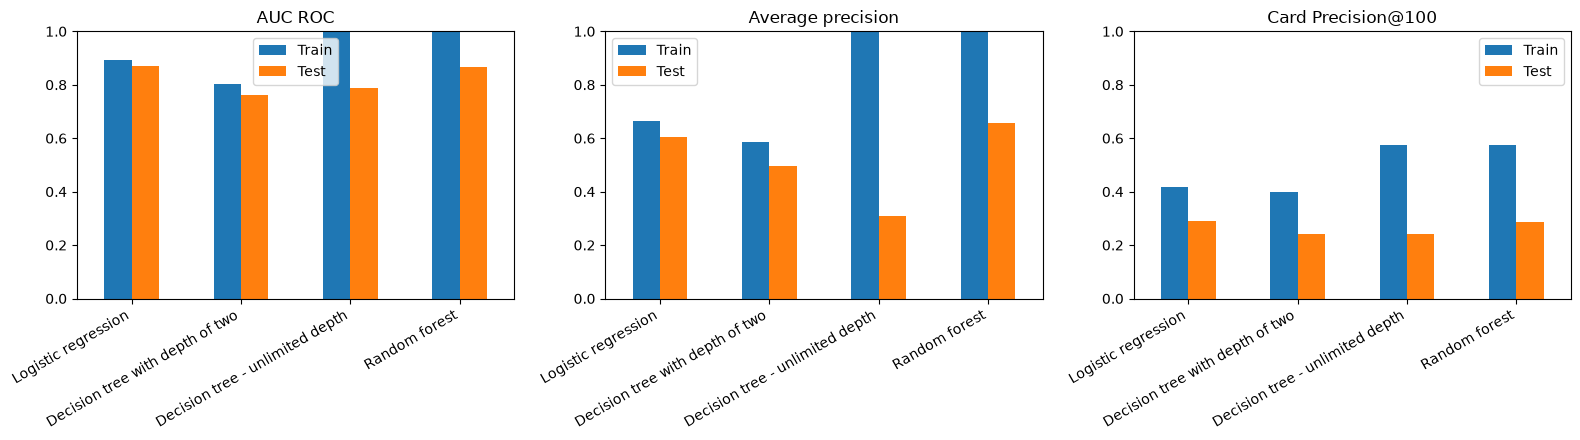

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, df_performances_test.columns):
    pd.DataFrame({"Train": df_performances_train[metric], "Test": df_performances_test[metric]}).plot.bar(ax=ax, rot=30)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.set_xticklabels(ax.get_xticklabels(), ha="right")
fig.tight_layout()

The model that overfits most is the unlimited-depth decision tree: near-perfect on the training set, much weaker on the test set. The ensemble models (random forest, and XGBoost if available) give the best test performance, which matches the handbook's results.

## 9. Trade-offs of the single-view design

* **Simple.** One entity, one feature view, and a training join that is a lookup by `TRANSACTION_ID`.
* **Not servable online.** The online store holds one row per entity key, and here the key is `TRANSACTION_ID`. That is why this notebook never calls `store.materialize`, even though `feast apply` created the online table:
  * Materializing would copy one row per *past* transaction (millions of rows) into the online store, and none of them would ever be read again.
  * When a new transaction arrives, its ID has never been stored, so `get_online_features` would return nothing for it.
  * The customer and terminal features would have to be computed outside Feast at request time and passed in with the request. Feast would then add nothing but the on-demand weekend/night flags.

  This design fits offline training and batch scoring of already-recorded transactions.
* **No reuse.** The customer and terminal features are tied to transactions, so another model that needs, say, customer spending per day can't reuse them.

The sibling notebook [01_fraud_detection_feast_natural_entities.ipynb](01_fraud_detection_feast_natural_entities.ipynb) keys the same features on `CUSTOMER_ID` and `TERMINAL_ID`. It produces the same training features (except for a few transactions with identical timestamps) and can also serve them online: it materializes them, scores incoming transactions, and pushes fresh values as transactions arrive.

## Summary

* The windowed customer and terminal features were computed with the handbook's pandas code and stored as daily-partitioned Parquet files. The weekend/night features are an **on-demand feature view** that Feast computes at retrieval time.
* Feature definitions were registered with `feast apply` / `store.apply` and inspected from the CLI and the SDK.
* `get_historical_features` built a point-in-time correct training set from an entity dataframe, quickly with DuckDB and slowly with Dask.